# PSI200 event-based dataset

PSI200 се записва на неравни интервали (~10 мин), останалите сензори - по-често.

Тук **не** разтягаме всичко до 1 час. Вместо това:

- **един ред = едно четене на PSI200** (това е target-ът)
- **всяка feature = средна стойност на сензора в интервала между предишното и текущото четене на PSI200**

За всяка feature пазим 4 колони: `_mean`, `_std`, `_n` (брой сурови проби), `_frozen` (мъртъв сензор).

`PSI80` е премахнат напълно - силно корелиран с PSI200, не участва в данните.

**Ред на изпълнение:** конфигурация -> read_raw -> build -> run, после всичко останало.

In [1]:
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

ENGINE = create_engine(
    'mssql+pyodbc:///?odbc_connect='
    'DRIVER={ODBC Driver 17 for SQL Server};SERVER=10.20.2.10;'
    'DATABASE=pulse;UID=Pulse_RO;PWD=PD@T@r3@der'
)

# feature -> { MillName: TagID }
SQL_TAGS = {
    'Ore':        {'Mill06': '500',  'Mill07': '455',  'Mill08': '467'},
    'WaterMill':  {'Mill06': '1219', 'Mill07': '461',  'Mill08': '474'},
    'WaterZumpf': {'Mill06': '1220', 'Mill07': '462',  'Mill08': '475'},
    'Power':      {'Mill06': '502',  'Mill07': '460',  'Mill08': '471'},
    'ZumpfLevel': {'Mill06': '501',  'Mill07': '458',  'Mill08': '470'},
    'PressureHC': {'Mill06': '1217', 'Mill07': '459',  'Mill08': '472'},
    'DensityHC':  {'Mill06': '1216', 'Mill07': '457',  'Mill08': '469'},
    'FE':         {'Mill06': '1762', 'Mill07': '1762', 'Mill08': '1762'},
    'PulpHC':     {'Mill06': '2777', 'Mill07': '2837', 'Mill08': '1833'},
    'PumpRPM':    {'Mill06': '2796', 'Mill07': '2856', 'Mill08': '1800'},
    'MotorAmp':   {'Mill06': '2770', 'Mill07': '2830', 'Mill08': '1805'},
    'PSI200':     {'Mill06': '5328', 'Mill07': '5330', 'Mill08': '5333'},
}

TABLE_NAMES = ['LoggerValues'] + [
    f'LoggerValues_Archive_{m}{y}'
    for y in (2026, 2025)
    for m in ('Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec')
    if not (y == 2026 and m in ('Oct', 'Nov', 'Dec'))
]

# PSI80 е премахнат напълно: силно корелиран с PSI200, не бива да участва в обучение/тест.
TARGET = 'PSI200'
FEATURES = [f for f in SQL_TAGS if f != TARGET]
print(f'{len(FEATURES)} features:', FEATURES)

11 features: ['Ore', 'WaterMill', 'WaterZumpf', 'Power', 'ZumpfLevel', 'PressureHC', 'DensityHC', 'FE', 'PulpHC', 'PumpRPM', 'MotorAmp']


In [2]:
def read_raw(start=None, end=None):
    """Сурови данни: {feature: {mill: Series}}. Без resample, без ffill."""
    tag_map = {}
    for feat, mills in SQL_TAGS.items():
        for mill, tag in mills.items():
            tag_map.setdefault(tag, []).append((feat, mill))

    tags = ','.join(tag_map)
    frames = []
    for tbl in TABLE_NAMES:
        q = f'SELECT IndexTime, LoggerTagID, Value FROM {tbl} WHERE LoggerTagID IN ({tags})'
        if start:
            q += f' AND IndexTime >= {start!r}'
        if end:
            q += f' AND IndexTime < {end!r}'
        d = pd.read_sql_query(q, ENGINE)
        print(f'{tbl:<32} {len(d):>8}')
        if not d.empty:
            frames.append(d)

    raw = pd.concat(frames, ignore_index=True)
    raw['LoggerTagID'] = raw['LoggerTagID'].astype(str)
    raw['IndexTime'] = pd.to_datetime(raw['IndexTime'])
    # dedup по (време, таг) - иначе при еднакъв IndexTime губим мелници
    raw = raw.drop_duplicates(['IndexTime', 'LoggerTagID'], keep='last').sort_values('IndexTime')

    out = {}
    for tag, targets in tag_map.items():
        s = raw.loc[raw['LoggerTagID'] == tag].set_index('IndexTime')['Value'].sort_index()
        s = s[~s.index.duplicated(keep='last')]
        for feat, mill in targets:
            out.setdefault(feat, {})[mill] = s
    return out

In [3]:
def build(raw, mill, lag=0, max_gap=60):
    """1 ред на PSI200 четене; features = mean/std/n в интервала до предишното четене."""
    psi = raw[TARGET][mill].dropna()
    edges = (psi.index - pd.Timedelta(minutes=lag)).values
    n = len(psi) - 1

    out = pd.DataFrame(index=psi.index[1:])
    out.index.name = 'TimeStamp'
    out[TARGET] = psi.values[1:]
    out['dt_sec'] = np.diff(psi.index.values) / np.timedelta64(1, 's')

    for feat in FEATURES:
        s = raw.get(feat, {}).get(mill)
        if s is None or s.dropna().empty:
            out[f'{feat}_mean'] = np.nan
            out[f'{feat}_std'] = np.nan
            out[f'{feat}_n'] = 0
            out[f'{feat}_frozen'] = True
            continue

        s = s.dropna()
        # в кой прозорец попада всяка сурова стойност
        pos = np.searchsorted(edges, s.index.values, side='left') - 1
        ok = (pos >= 0) & (pos < n)
        g = pd.DataFrame({'pos': pos[ok], 'v': s.values[ok]}).groupby('pos')['v']
        st = pd.DataFrame({'mean': g.mean(), 'std': g.std(), 'n': g.count()}).reindex(range(n))

        out[f'{feat}_mean'] = st['mean'].values
        out[f'{feat}_std'] = st['std'].values
        out[f'{feat}_n'] = st['n'].fillna(0).astype(int).values
        # замръзнал: >1 проба, но всички еднакви
        out[f'{feat}_frozen'] = ((st['n'] > 1) & (st['std'].fillna(0) == 0)).values

    out['n_features_ok'] = out[[f'{f}_mean' for f in FEATURES]].notna().sum(axis=1)
    if max_gap:
        out = out[out['dt_sec'] <= max_gap * 60]
    return out

In [4]:
def clean(df, min_coverage=0.5):
    """Запълва NaN в features. Връща (df, keep, dropped).

    - features с покритие < min_coverage се изхвърлят (няма смисъл да се запълват)
    - _std при n == 1 -> 0 (има проба, но няма вариация)
    - празен прозорец (n == 0) -> ffill, после bfill за началото
    """
    coverage = {f: (df[f'{f}_n'] > 0).mean() for f in FEATURES}
    keep = [f for f in FEATURES if coverage[f] >= min_coverage]
    dropped = [f for f in FEATURES if f not in keep]

    out = df.copy()
    for f in keep:
        n = out[f'{f}_n']
        out[f'{f}_std'] = out[f'{f}_std'].mask(n == 1, 0.0).ffill().bfill()
        out[f'{f}_mean'] = out[f'{f}_mean'].ffill().bfill()

    # колко features са били запълнени в реда (не са имали нито една проба)
    out['n_ffilled'] = sum((out[f'{f}_n'] == 0).astype(int) for f in keep)

    out = out.drop(columns=[f'{f}_{s}' for f in dropped for s in ('mean', 'std', 'n', 'frozen')],
                   errors='ignore')
    out = out.drop(columns=['n_features_ok'], errors='ignore')
    return out, keep, dropped

In [5]:
# период на селекция (край преди аварията на PSI200: Oct 4-21 сензорът е мъртъв)
START, END = '2026-01-01', '2026-02-28'
raw = read_raw(START, END)
df, keep, dropped = clean(build(raw, 'Mill06'))

print('Изхвърлени (покритие < 50%):', dropped)
print('Останали features:', len(keep), '->', keep)
print()

feat_cols = [f'{f}_{s}' for f in keep for s in ('mean', 'std', 'n', 'frozen')]
counts = df[feat_cols].notna().sum()
print('Редове:', len(df))
print('Non-null по feature колони (уникални):', counts.unique())
print('Всички равни и пълни:', counts.nunique() == 1 and counts.iloc[0] == len(df))
print()

FEATURES = keep   # за да работят клетките по-долу
df.info()

LoggerValues                            0
LoggerValues_Archive_Jan2026      3250466
LoggerValues_Archive_Feb2026      2914418
LoggerValues_Archive_Mar2026            0
LoggerValues_Archive_Apr2026            0
LoggerValues_Archive_May2026            0
LoggerValues_Archive_Jun2026            0
LoggerValues_Archive_Jul2026            0
LoggerValues_Archive_Aug2026            0
LoggerValues_Archive_Sep2026            0
LoggerValues_Archive_Jan2025            0
LoggerValues_Archive_Feb2025            0
LoggerValues_Archive_Mar2025            0
LoggerValues_Archive_Apr2025            0
LoggerValues_Archive_May2025            0
LoggerValues_Archive_Jun2025            0
LoggerValues_Archive_Jul2025            0
LoggerValues_Archive_Aug2025            0
LoggerValues_Archive_Sep2025            0
LoggerValues_Archive_Oct2025            0
LoggerValues_Archive_Nov2025            0
LoggerValues_Archive_Dec2025            0
Изхвърлени (покритие < 50%): ['FE', 'PumpRPM']
Останали features: 9 -> ['Ore

In [6]:
df.describe()

,PSI200,dt_sec,Ore_mean,Ore_std,Ore_n,WaterMill_mean,WaterMill_std,WaterMill_n,WaterZumpf_mean,WaterZumpf_std,WaterZumpf_n,Power_mean,Power_std,Power_n,ZumpfLevel_mean,ZumpfLevel_std,ZumpfLevel_n,PressureHC_mean,PressureHC_std,PressureHC_n,DensityHC_mean,DensityHC_std,DensityHC_n,PulpHC_mean,PulpHC_std,PulpHC_n,MotorAmp_mean,MotorAmp_std,MotorAmp_n,n_ffilled
count,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000,6506.000000
mean,20.270658,708.921509,169.812821,1.025627,2.717030,9.687862,0.166676,50.798494,170.636587,6.796511,23.560713,1850.203627,51.552185,69.087919,1575.404149,27.923371,62.900246,0.433790,0.006121,56.225177,1661.173478,3.018373,26.112050,481.908945,3.620172,33.407624,196.146341,5.592348,63.050569,0.354596
std,3.172794,437.328272,10.960582,3.601075,2.834184,4.155380,0.250241,35.995262,31.490656,6.967491,20.170048,82.795069,7.145153,42.676485,35.996794,18.907962,39.290969,0.049731,0.008683,35.328991,32.650839,3.746966,17.583958,67.608174,5.148665,22.215543,8.724936,0.752450,39.119821,0.529665
min,0.000000,21.550000,13.095250,0.000000,0.000000,0.133800,0.000000,0.000000,54.138333,0.000000,0.000000,1527.638352,32.847452,2.000000,351.070159,0.000000,1.000000,0.141480,0.001250,0.000000,1297.394737,0.000000,0.000000,92.650341,0.000000,1.000000,163.054593,3.595323,2.000000,0.000000
25%,18.200000,474.664000,166.420000,0.681340,0.000000,7.841869,0.039281,35.000000,150.344434,1.644662,11.000000,1790.932011,47.975818,46.000000,1563.316510,14.901926,43.000000,0.407596,0.003469,37.000000,1640.379990,1.811588,16.000000,442.595165,2.159125,20.000000,189.966801,5.208105,42.000000,0.000000
50%,20.000000,479.683500,170.167750,0.761505,2.000000,10.276169,0.108951,41.000000,167.389583,4.589661,19.000000,1817.458892,51.341263,47.000000,1579.508062,23.272387,46.000000,0.448886,0.004290,40.000000,1660.653271,2.449023,20.000000,496.995835,2.760534,25.000000,192.677896,5.566482,44.000000,0.000000
75%,22.200000,944.948250,175.170167,0.876812,4.000000,12.901362,0.229799,57.000000,189.026604,9.572731,29.000000,1950.909957,54.812899,92.000000,1585.763136,38.167627,79.000000,0.464825,0.005771,71.000000,1678.729687,3.356909,30.000000,523.022008,3.731202,39.000000,207.149038,5.940616,83.000000,1.000000
max,49.800000,3535.943000,192.720000,84.059411,33.000000,22.771047,9.075114,300.000000,262.030375,70.244040,248.000000,2024.992609,312.916625,349.000000,1683.566087,431.299948,334.000000,0.559732,0.189104,312.000000,1770.321875,90.512279,153.000000,610.353552,119.489760,237.000000,214.252071,35.064364,326.000000,3.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6506 entries, 2026-01-01 00:22:20.573000 to 2026-02-27 23:48:21.843000
Data columns (total 39 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   PSI200             6506 non-null   float64
 1   dt_sec             6506 non-null   float64
 2   Ore_mean           6506 non-null   float64
 3   Ore_std            6506 non-null   float64
 4   Ore_n              6506 non-null   int64  
 5   Ore_frozen         6506 non-null   bool   
 6   WaterMill_mean     6506 non-null   float64
 7   WaterMill_std      6506 non-null   float64
 8   WaterMill_n        6506 non-null   int64  
 9   WaterMill_frozen   6506 non-null   bool   
 10  WaterZumpf_mean    6506 non-null   float64
 11  WaterZumpf_std     6506 non-null   float64
 12  WaterZumpf_n       6506 non-null   int64  
 13  WaterZumpf_frozen  6506 non-null   bool   
 14  Power_mean         6506 non-null   float64
 15  Power_std          650

C:\Users\s.lyubenov\AppData\Local\Temp\ipykernel_49756\4181230360.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


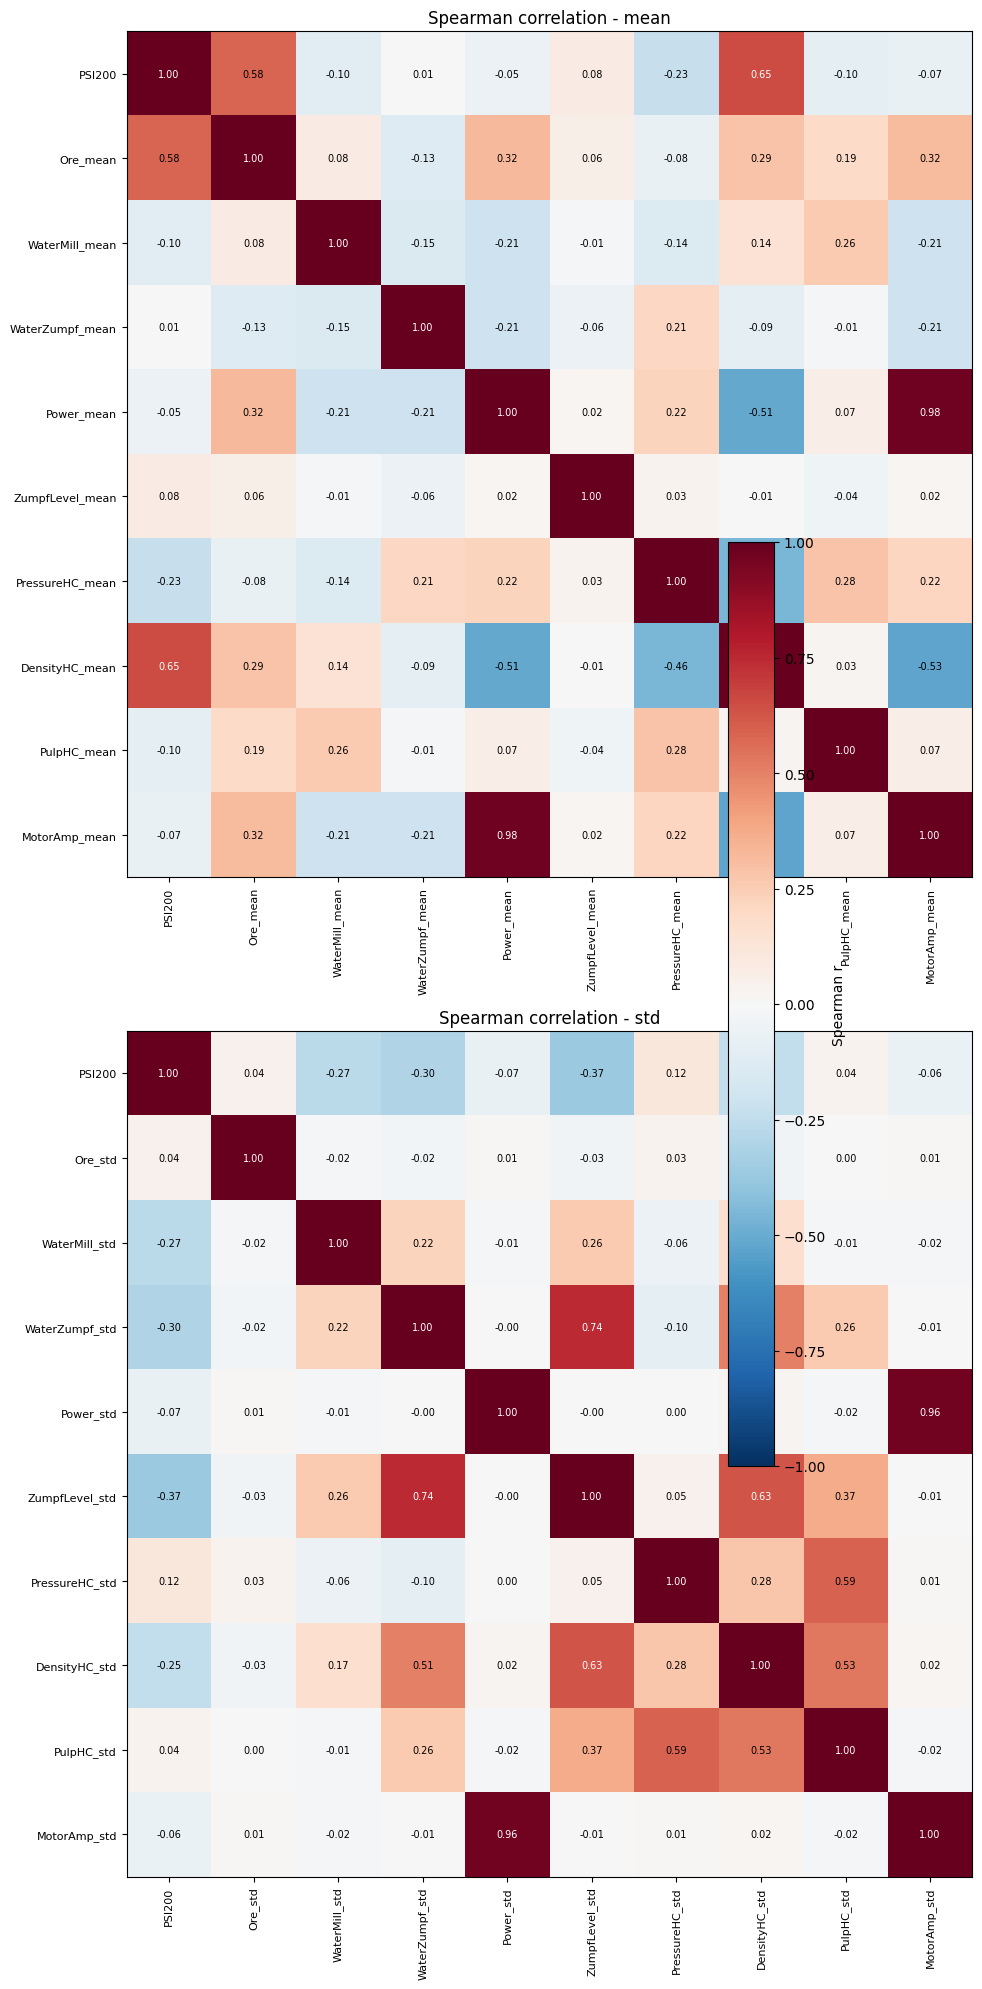

In [8]:
import matplotlib.pyplot as plt


def corr_block(kind):
    cols = [TARGET] + [f'{f}_{kind}' for f in FEATURES]
    return cols, df[cols].corr(method='spearman')


def draw(ax, cols, corr, title):
    im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels(cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = corr.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(v) > 0.6 else 'black')
    ax.set_title(title)
    return im


fig, axes = plt.subplots(2, 1, figsize=(12, 20))

for ax, kind in zip(axes, ('mean', 'std')):
    cols, corr = corr_block(kind)
    im = draw(ax, cols, corr, f'Spearman correlation - {kind}')

fig.colorbar(im, ax=axes, shrink=.6, label='Spearman r')
plt.tight_layout()
plt.show()

In [9]:
# 1. Features / target + хронологичен train/test split
# само _mean частта - _std се изключва
DROP_FEATURES = ['ZumpfLevel', 'Power']
FEAT_COLS = [f'{f}_mean' for f in FEATURES if f not in DROP_FEATURES]

X = df[FEAT_COLS].astype(float)
y = df[TARGET].astype(float)

# филтри преди split
mask_target = y.between(15, 30)          # PSI200 извън [15, 30]
mask_ore = X['Ore_mean'] >= 120          # Ore < 120
mask = mask_target & mask_ore

print(f'Изхвърлени по target (PSI200 < 15 или > 30): {int((~mask_target).sum())} от {len(y)}')
print(f'Изхвърлени по Ore_mean < 120:               {int((~mask_ore).sum())} от {len(y)}')
print(f'Остават след филтрите:                      {int(mask.sum())} реда')
X, y = X[mask], y[mask]

# ВАЖНО: данните са времеви ред -> split по време, НЕ random.
# Иначе моделът "вижда" бъдещето и резултатите са фалшиво добри.
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print()
print(f'X: {X.shape}   ({len(FEAT_COLS)} features, само _mean)')
print(f'train: {len(X_train):>6} реда   {X_train.index.min()}  ..  {X_train.index.max()}')
print(f'test : {len(X_test):>6} реда   {X_test.index.min()}  ..  {X_test.index.max()}')
print()
print(f'target {TARGET}: mean={y.mean():.3f}  std={y.std():.3f}  '
      f'min={y.min():.3f}  max={y.max():.3f}')
print(f'NaN в X: {int(X.isna().sum().sum())}   NaN в y: {int(y.isna().sum())}')
print()
print('Features:', FEAT_COLS)

Изхвърлени по target (PSI200 < 15 или > 30): 141 от 6506
Изхвърлени по Ore_mean < 120:               40 от 6506
Остават след филтрите:                      6354 реда

X: (6354, 7)   (7 features, само _mean)
train:   5083 реда   2026-01-01 00:22:20.573000  ..  2026-02-18 07:58:11.420000
test :   1271 реда   2026-02-18 08:06:06.640000  ..  2026-02-27 23:48:21.843000

target PSI200: mean=20.268  std=2.636  min=15.000  max=30.000
NaN в X: 0   NaN в y: 0

Features: ['Ore_mean', 'WaterMill_mean', 'WaterZumpf_mean', 'PressureHC_mean', 'DensityHC_mean', 'PulpHC_mean', 'MotorAmp_mean']


In [10]:
# 2. Preprocessing pipeline
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# XGBoost е дървовиден модел -> не се нуждае от StandardScaler.
# Оставяме само imputer, за да е явно и да работи и с NaN.
num_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
])

print(num_pipeline)

Pipeline(steps=[('impute', SimpleImputer(strategy='median'))])


In [11]:
# 3. Helper за оценка на модел
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluate(name, model):
    """Fit-ва модела и връща метриките за train и test."""
    model.fit(X_train, y_train)
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)

    row = {
        'model': name,
        'rmse_train': mean_squared_error(y_train, pred_tr) ** 0.5,
        'rmse_test': mean_squared_error(y_test, pred_te) ** 0.5,
        'mae_test': mean_absolute_error(y_test, pred_te),
        'r2_test': r2_score(y_test, pred_te),
    }
    print(f'{name:<20} RMSE train={row["rmse_train"]:8.3f}   '
          f'test={row["rmse_test"]:8.3f}   '
          f'MAE={row["mae_test"]:7.3f}   R2={row["r2_test"]:6.3f}')
    return row


print('Готово.')

Готово.


In [12]:
# 4. XGBoost - обучение
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

xgb_reg = make_pipeline(num_pipeline, XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
    objective='reg:squarederror',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
))

xgb_result = evaluate('XGBoost', xgb_reg)

XGBoost              RMSE train=   0.547   test=   2.205   MAE=  1.712   R2= 0.519


In [13]:
# 5. Cross-validation (XGBoost)
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

# KFold - както в книгата, но разбърква времето -> оптимистична оценка
kf = -cross_val_score(xgb_reg, X, y, scoring='neg_root_mean_squared_error',
                      cv=KFold(5, shuffle=True, random_state=42), n_jobs=-1)
# TimeSeriesSplit - train винаги е ПРЕДИ validation -> честна оценка
ts = -cross_val_score(xgb_reg, X, y, scoring='neg_root_mean_squared_error',
                      cv=TimeSeriesSplit(n_splits=5), n_jobs=-1)

print(f'KFold        RMSE: {kf.mean():8.3f} ± {kf.std():5.3f}   {np.round(kf, 2)}')
print(f'TimeSeries   RMSE: {ts.mean():8.3f} ± {ts.std():5.3f}   {np.round(ts, 2)}')
print()
print('KFold е по-нисък, защото "вижда" бъдещи редове. Гледай TimeSeries реда.')

KFold        RMSE:    1.197 ± 0.037   [1.24 1.16 1.18 1.16 1.24]
TimeSeries   RMSE:    2.111 ± 0.632   [1.5  3.21 2.06 1.49 2.29]

KFold е по-нисък, защото "вижда" бъдещи редове. Гледай TimeSeries реда.


Feature importance:
DensityHC_mean     0.3090
PulpHC_mean        0.2101
MotorAmp_mean      0.1384
Ore_mean           0.1148
WaterMill_mean     0.0811
PressureHC_mean    0.0761
WaterZumpf_mean    0.0705

Сума на top 5: 0.853   брой features с importance < 0.01: 0


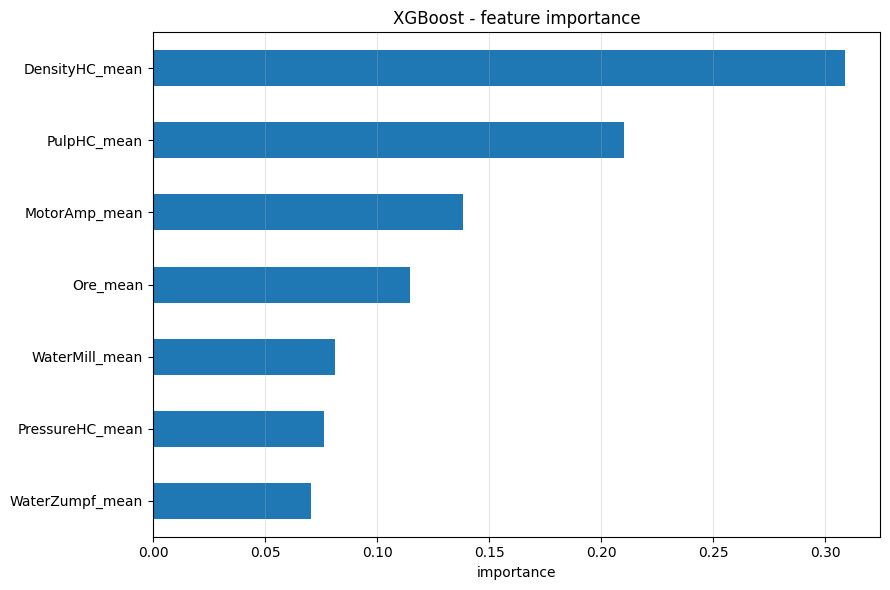

In [14]:
# 6. Feature importance (XGBoost)
import matplotlib.pyplot as plt

xgb = xgb_reg.named_steps['xgbregressor']
imp = pd.Series(xgb.feature_importances_, index=FEAT_COLS).sort_values(ascending=False)

print('Feature importance:')
print(imp.round(4).to_string())
print()
print(f'Сума на top 5: {imp.head(5).sum():.3f}   '
      f'брой features с importance < 0.01: {(imp < 0.01).sum()}')

ax = imp[::-1].plot.barh(figsize=(9, 6))
ax.set_xlabel('importance')
ax.set_title('XGBoost - feature importance')
ax.grid(axis='x', alpha=.3)
plt.tight_layout()
plt.show()

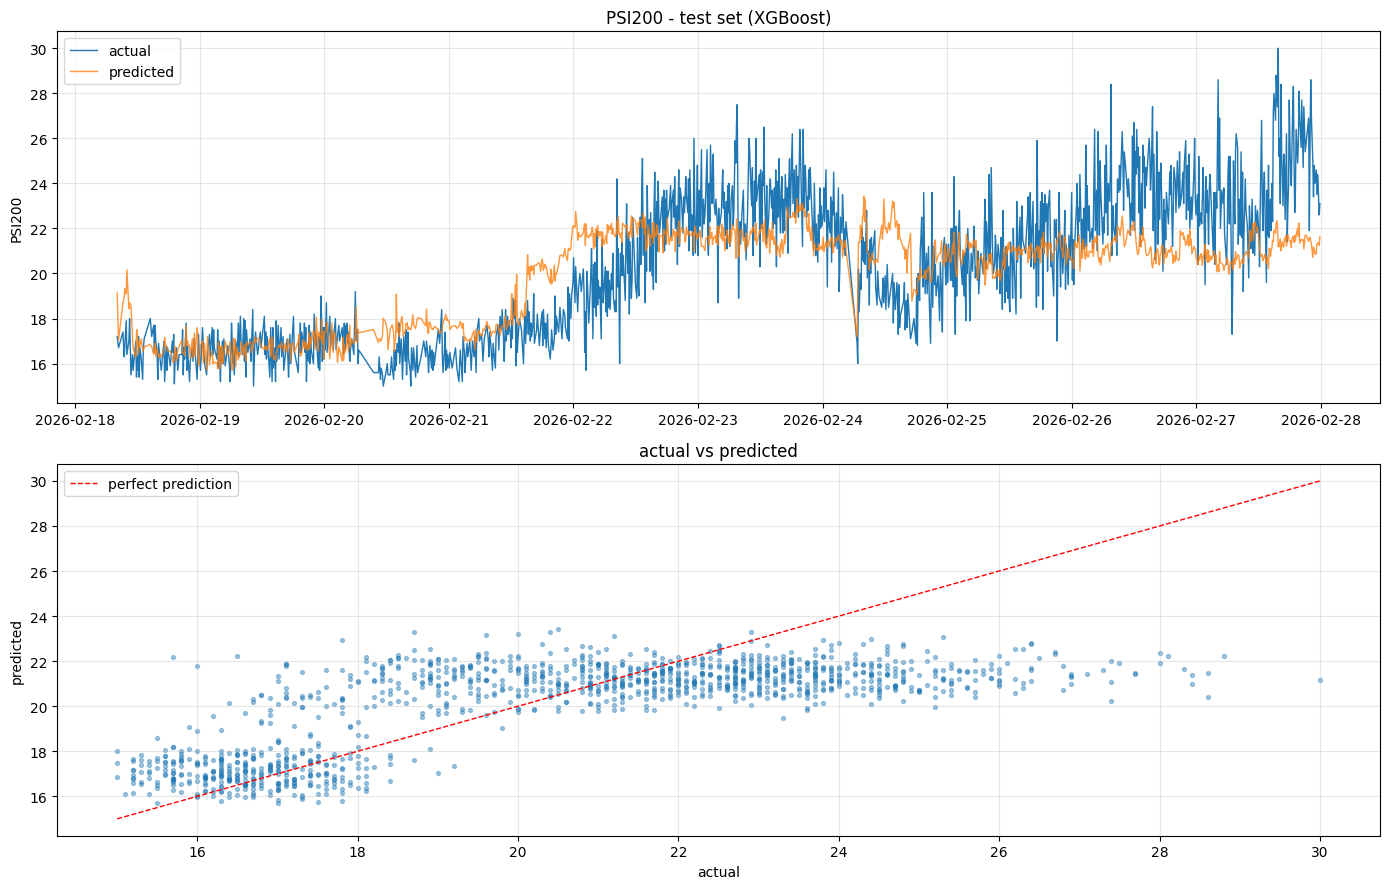

In [15]:
# 7. Predictions vs actual (test set, XGBoost)
pred_test = xgb_reg.predict(X_test)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(y_test.index, y_test.values, label='actual', lw=1)
axes[0].plot(y_test.index, pred_test, label='predicted', lw=1, alpha=.8)
axes[0].set_title(f'{TARGET} - test set (XGBoost)')
axes[0].set_ylabel(TARGET)
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].scatter(y_test, pred_test, s=8, alpha=.4)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[1].plot(lims, lims, 'r--', lw=1, label='perfect prediction')
axes[1].set_xlabel('actual')
axes[1].set_ylabel('predicted')
axes[1].set_title('actual vs predicted')
axes[1].legend()
axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

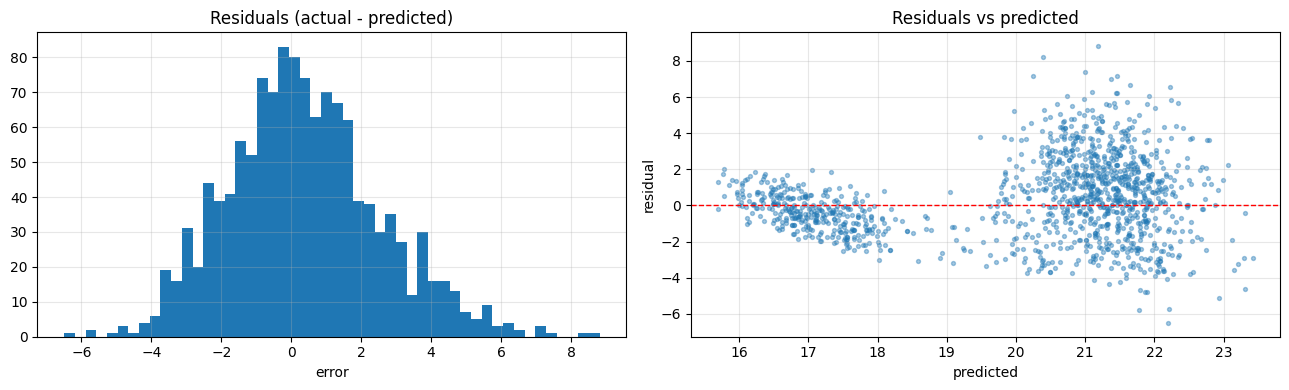

count    1271.000
mean        0.364
std         2.175
min        -6.497
25%        -1.077
50%         0.217
75%         1.645
max         8.817

Bias (mean residual): 0.364
RMSE: 2.205


In [16]:
# 8. Residuals (test set, XGBoost)
pred_test = xgb_reg.predict(X_test)
resid = y_test - pred_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(resid, bins=50)
axes[0].set_title('Residuals (actual - predicted)')
axes[0].set_xlabel('error')
axes[0].grid(alpha=.3)

axes[1].scatter(pred_test, resid, s=8, alpha=.4)
axes[1].axhline(0, color='r', ls='--', lw=1)
axes[1].set_xlabel('predicted')
axes[1].set_ylabel('residual')
axes[1].set_title('Residuals vs predicted')
axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

print(resid.describe().round(3).to_string())
print()
print(f'Bias (mean residual): {resid.mean():.3f}')
print(f'RMSE: {(resid ** 2).mean() ** 0.5:.3f}')

## v2 — feature engineering, baselines и честна валидация

Диагноза на v1: `R2 = -0.18`, `bias = +0.76`, `resid.std ≈ y.std` -> моделът не хваща нищо извън train.

Стъпки тук:

1. **CCF** - при кой лаг всяка feature е най-информативна (dead time на мелницата).
2. **Feature engineering** - авторегресия на PSI200 (лагове, rolling, diff-ове върху `shift(1)`), физични отношения.
3. **Базови модели** - persistence / rolling mean / linear. Без тях не знаем дали XGBoost има смисъл.
4. **XGBoost v2** - по-плитки дървета, early stopping на времеви validation.
5. **Δ-target** - прогноза на промяната вместо нивото (маха отместването между периодите).
6. **Walk-forward** с gap - честна оценка по цялата история.

Всичко се смята върху `df` **преди** филтрите, за да са лаговете коректни.

Най-добър лаг (в брой PSI200 четения, ~8 мин всяко):
        feature  best_lag  spearman
 DensityHC_mean         0     0.649
       Ore_mean         1     0.584
PressureHC_mean        24    -0.239
 WaterMill_mean        22    -0.128
    PulpHC_mean        24    -0.118
ZumpfLevel_mean         0     0.085
  MotorAmp_mean         1    -0.077
     Power_mean         1    -0.057
WaterZumpf_mean       -24     0.050

best_lag > 0 -> feature-ът изостава и трябва да влезе като shift(best_lag).


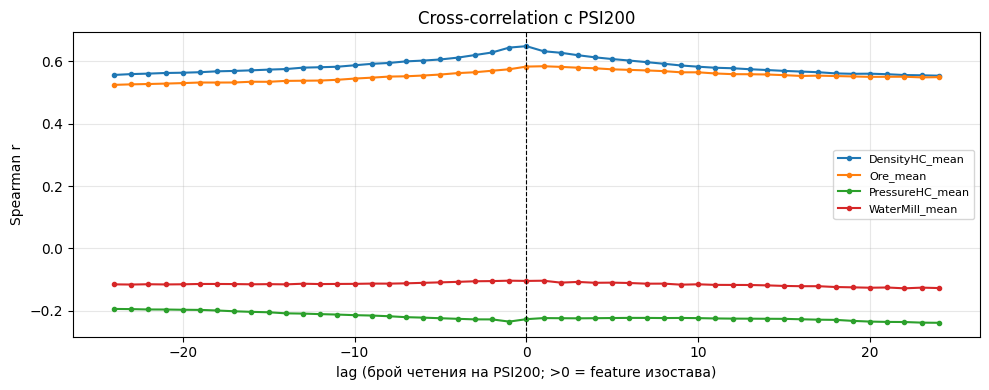

In [17]:
# 9a. Cross-correlation: при кой лаг всяка feature е най-информативна
# lag > 0 означава, че feature-ът изостава спрямо PSI200 (минало -> настояще)


def ccf_best(d, cols, max_lag=24):
    y = d[TARGET]
    rows = []
    for c in cols:
        s = d[c]
        best_lag, best_r = 0, np.nan
        for lag in range(-max_lag, max_lag + 1):
            r = y.corr(s.shift(lag), method='spearman')
            if np.isfinite(r) and (not np.isfinite(best_r) or abs(r) > abs(best_r)):
                best_lag, best_r = lag, r
        rows.append({'feature': c, 'best_lag': best_lag, 'spearman': best_r})
    return pd.DataFrame(rows).sort_values('spearman', key=lambda s: s.abs(), ascending=False)


mean_cols = [f'{f}_mean' for f in FEATURES]
ccf = ccf_best(df, mean_cols, max_lag=24)
print('Най-добър лаг (в брой PSI200 четения, ~8 мин всяко):')
print(ccf.round(3).to_string(index=False))
print()
print('best_lag > 0 -> feature-ът изостава и трябва да влезе като shift(best_lag).')

# CCF крива за top 4 features
top = ccf.head(4)['feature'].tolist()
lags = np.arange(-24, 25)
fig, ax = plt.subplots(figsize=(10, 4))
for c in top:
    r = [df[TARGET].corr(df[c].shift(l), method='spearman') for l in lags]
    ax.plot(lags, r, marker='o', ms=3, label=c)
ax.axvline(0, color='k', lw=.8, ls='--')
ax.set_xlabel('lag (брой четения на PSI200; >0 = feature изостава)')
ax.set_ylabel('Spearman r')
ax.set_title('Cross-correlation с PSI200')
ax.legend(fontsize=8)
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

In [ ]:
# 9b. Feature engineering v2
# ВАЖНО: всичко се смята върху ПЪЛНИЯ df, ПРЕДИ филтрите, за да са лаговете коректни.
# PSI80 е премахнат напълно (силно корелиран с PSI200) - не участва като feature/target.


def add_features(d):
    out = d.copy()
    # PSI200 има глитчи (max 6553 при норма ~15-30). Ако не ги махнем ПРЕДИ лаговете,
    # psi_lag1 и всички rolling статистики се замърсяват, а ΔPSI200 става ~6500.
    psi = out[TARGET].where(out[TARGET].between(15, 30))
    eps = 1e-6

    # --- авторегресивни: собствената история на PSI200 (без текущата стойност) ---
    for k in (1, 2, 3, 6, 12):
        out[f'psi_lag{k}'] = psi.shift(k)
    for w in (3, 6, 12):
        r = psi.shift(1).rolling(w, min_periods=1)
        out[f'psi_roll{w}_mean'] = r.mean()
        out[f'psi_roll{w}_std'] = r.std()
        out[f'psi_roll{w}_min'] = r.min()
        out[f'psi_roll{w}_max'] = r.max()
    # diff-овете ЗАДЪЛЖИТЕЛНО се смятат върху shift(1), иначе съдържат текущия target:
    # psi.diff(1) = y_t - y_{t-1}, т.е. psi_diff1 + psi_lag1 == y_t (перфектна реконструкция).
    base = psi.shift(1)
    out['psi_diff1'] = base.diff(1)
    out['psi_diff3'] = base.diff(3)
    out['psi_slope6'] = (psi.shift(1) - psi.shift(6)) / 5.0

    # --- ниво + скорост на промяна за всяка _mean feature ---
    for f in FEATURES:
        c = f'{f}_mean'
        if c in out.columns:
            out[f'{f}_lag1'] = out[c].shift(1)
            out[f'{f}_diff1'] = out[c].diff(1)

    # --- производни физични отношения (само ако нужните колони съществуват) ---
    # при по-дълъг период част от features падат по покритие -> не бива да гърмим.
    if {'WaterMill_mean', 'Ore_mean'} <= set(out.columns):
        out['dilution_mill'] = out['WaterMill_mean'] / (out['Ore_mean'] + eps)
    if {'WaterZumpf_mean', 'Ore_mean'} <= set(out.columns):
        out['dilution_zumpf'] = out['WaterZumpf_mean'] / (out['Ore_mean'] + eps)
    if {'Ore_mean', 'PulpHC_mean'} <= set(out.columns):
        out['solids_load'] = out['Ore_mean'] * out['PulpHC_mean']
    if {'Power_mean', 'Ore_mean'} <= set(out.columns):
        out['spec_energy'] = out['Power_mean'] / (out['Ore_mean'] + eps)
    if {'MotorAmp_mean', 'PumpRPM_mean'} <= set(out.columns):
        out['amp_per_rpm'] = out['MotorAmp_mean'] / (out['PumpRPM_mean'] + eps)
    if {'DensityHC_mean', 'PulpHC_mean'} <= set(out.columns):
        out['density_minus_pulp'] = out['DensityHC_mean'] - out['PulpHC_mean']

    return out


n_glitch = int((~df[TARGET].between(15, 30)).sum())
print(f'PSI200 глитчи (извън [15, 30]), изчистени преди лаговете: {n_glitch}')

df2 = add_features(df)

# същите филтри като в клетка 9
mask = df2[TARGET].between(15, 30) & (df2['Ore_mean'] >= 120)
df2 = df2[mask].copy()

# махаме загряващите редове + редовете веднага след глитч (psi_lag1 = NaN)
df2 = df2.dropna(subset=['psi_lag12', 'psi_lag1'])

# --- кои колони влизат в модела ---
BASE_COLS = [f'{f}_{s}' for f in FEATURES for s in ('mean', 'std')]
ENG_COLS = [c for c in df2.columns
            if c.startswith('psi_')
            or c.endswith(('_lag1', '_diff1'))
            or c in ('dilution_mill', 'dilution_zumpf', 'solids_load', 'spec_energy',
                     'amp_per_rpm', 'density_minus_pulp', 'dt_sec', 'n_ffilled')]
FEAT_COLS2 = [c for c in dict.fromkeys(BASE_COLS + ENG_COLS) if c in df2.columns]

# --- leakage guard: никоя feature не бива да е почти перфектно копие на target ---
LEAK_CORR = 0.995
corr_with_target = df2[FEAT_COLS2].corrwith(df2[TARGET]).abs()
leaky = corr_with_target[corr_with_target > LEAK_CORR].round(4).to_dict()
assert not leaky, f'Възможен target leakage (|corr| > {LEAK_CORR}): {leaky}'
print(f'Leakage guard OK: max |corr(feature, target)| = {corr_with_target.max():.3f}')

split_idx2 = int(len(df2) * 0.8)
train2, test2 = df2.iloc[:split_idx2], df2.iloc[split_idx2:]
X_train2, y_train2 = train2[FEAT_COLS2].astype(float), train2[TARGET].astype(float)
X_test2, y_test2 = test2[FEAT_COLS2].astype(float), test2[TARGET].astype(float)

print(f'df2: {df2.shape}   features: {len(FEAT_COLS2)}')
print(f'train: {len(X_train2):>6}   {X_train2.index.min()}  ..  {X_train2.index.max()}')
print(f'test : {len(X_test2):>6}   {X_test2.index.min()}  ..  {X_test2.index.max()}')
print()
print('Нови features:', [c for c in FEAT_COLS2 if c not in FEAT_COLS])

PSI200 глитчи (извън [15, 30]), изчистени преди лаговете: 141


KeyError: 'PumpRPM_mean'

In [ ]:
# 9c. Базови модели - без тях не знаем дали XGBoost въобще има смисъл
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5


def score_row(name, y_true, pred):
    return {'model': name,
            'rmse': rmse(y_true, pred),
            'mae': mean_absolute_error(y_true, pred),
            'r2': r2_score(y_true, pred)}


rows = [
    score_row('train mean', y_test2, np.full(len(y_test2), y_train2.mean())),
    score_row('persistence (psi_lag1)', y_test2, X_test2['psi_lag1']),
    score_row('rolling mean 3', y_test2, X_test2['psi_roll3_mean']),
    score_row('rolling mean 12', y_test2, X_test2['psi_roll12_mean']),
]

# линейна регресия върху старите 8 _mean features (същият split като v1)
lin = LinearRegression().fit(X_train[FEAT_COLS], y_train)
rows.append(score_row('linear (8 _mean)', y_test, lin.predict(X_test[FEAT_COLS])))

baselines = pd.DataFrame(rows)
print(baselines.round(3).to_string(index=False))
print()
print('Ако persistence бие XGBoost -> проблемът е във features, не в модела.')

In [ ]:
# 9d. XGBoost v2 - по-плитки дървета + early stopping на времеви validation
from xgboost import XGBRegressor

# GAP между train и validation: без него validation е съседен по време на train и
# AR features го правят тривиален -> early stopping никога не спира (best_iteration = cap).
val_idx = int(len(X_train2) * 0.85)
GAP = 12
tr_end = val_idx - GAP

Xtr, Xval = X_train2.iloc[:tr_end], X_train2.iloc[val_idx:]
ytr, yval = y_train2.iloc[:tr_end], y_train2.iloc[val_idx:]

xgb2 = XGBRegressor(
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=15,
    reg_lambda=2.0,
    reg_alpha=0.5,
    objective='reg:squarederror',
    eval_metric='rmse',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=100,
)
xgb2.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
print(f'best_iteration: {xgb2.best_iteration}   (cap = 3000, GAP = {GAP})')

pred_tr2 = xgb2.predict(X_train2)
pred_te2 = xgb2.predict(X_test2)
print(f'XGB v2   RMSE train={rmse(y_train2, pred_tr2):7.3f}   '
      f'test={rmse(y_test2, pred_te2):7.3f}   '
      f'MAE={mean_absolute_error(y_test2, pred_te2):6.3f}   '
      f'R2={r2_score(y_test2, pred_te2):6.3f}')

imp2 = pd.Series(xgb2.feature_importances_, index=FEAT_COLS2).sort_values(ascending=False)
print()
print('Top 15 features:')
print(imp2.head(15).round(4).to_string())

In [ ]:
# 9e. Вариант с target = промяна (ΔPSI200) - маха отместването между периодите
y_delta = df2[TARGET] - df2['psi_lag1']
yd_train = y_delta.iloc[:split_idx2]
yd_test = y_delta.iloc[split_idx2:]

# sanity check: ΔPSI200 трябва да е в рамките на [15, 30] минус [15, 30], т.е. |Δ| <= 15
print(f'Δ train: min={yd_train.min():7.2f}  max={yd_train.max():7.2f}  std={yd_train.std():6.2f}')
print(f'Δ test : min={yd_test.min():7.2f}  max={yd_test.max():7.2f}  std={yd_test.std():6.2f}')
print()

xgb_d = XGBRegressor(
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=15,
    reg_lambda=2.0,
    reg_alpha=0.5,
    objective='reg:squarederror',
    eval_metric='rmse',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=100,
)
xgb_d.fit(Xtr, yd_train.iloc[:tr_end],
          eval_set=[(Xval, yd_train.iloc[val_idx:])], verbose=False)

# реконструкция на нивото: последно известно + предсказана промяна
pred_delta = xgb_d.predict(X_test2)
pred_level_d = X_test2['psi_lag1'].values + pred_delta

print(f'Δ-target  RMSE test={rmse(y_test2, pred_level_d):7.3f}   '
      f'MAE={mean_absolute_error(y_test2, pred_level_d):6.3f}   '
      f'R2={r2_score(y_test2, pred_level_d):6.3f}')
print(f'  RMSE на самата Δ: {rmse(yd_test, pred_delta):.3f}   '
      f'(std на Δ: {yd_test.std():.3f})')

In [ ]:
# 9f. Walk-forward валидация с gap - честна оценка върху ЦЯЛАТА история (train + test)
from sklearn.model_selection import TimeSeriesSplit


def walk_forward(X, y, n_splits=5, gap=12, **params):
    tscv = TimeSeriesSplit(n_splits=n_splits, gap=gap)
    out = []
    for i, (tr, va) in enumerate(tscv.split(X), 1):
        m = XGBRegressor(**params)
        m.fit(X.iloc[tr], y.iloc[tr], verbose=False)
        p = m.predict(X.iloc[va])
        out.append({'fold': i, 'n_val': len(va),
                    'rmse': rmse(y.iloc[va], p),
                    'r2': r2_score(y.iloc[va], p)})
    return pd.DataFrame(out)


wf_params = dict(
    n_estimators=min(max(xgb2.best_iteration + 1, 50), 800),
    learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.7,
    min_child_weight=15, reg_lambda=2.0, reg_alpha=0.5,
    objective='reg:squarederror', tree_method='hist', random_state=42, n_jobs=-1,
)

X_all = df2[FEAT_COLS2].astype(float)
y_all = df2[TARGET].astype(float)
wf = walk_forward(X_all, y_all, n_splits=5, gap=12, **wf_params)
print(wf.round(3).to_string(index=False))
print()
print(f'walk-forward RMSE: {wf["rmse"].mean():.3f} ± {wf["rmse"].std():.3f}')

In [ ]:
# 9g. Обобщение + графика
summary = pd.DataFrame([
    {'model': 'XGBoost v1 (8 _mean)', 'rmse_test': xgb_result['rmse_test'],
     'mae_test': xgb_result['mae_test'], 'r2_test': xgb_result['r2_test']},
    {'model': 'XGBoost v2 (level)', 'rmse_test': rmse(y_test2, pred_te2),
     'mae_test': mean_absolute_error(y_test2, pred_te2),
     'r2_test': r2_score(y_test2, pred_te2)},
    {'model': 'XGBoost v2 (Δ target)', 'rmse_test': rmse(y_test2, pred_level_d),
     'mae_test': mean_absolute_error(y_test2, pred_level_d),
     'r2_test': r2_score(y_test2, pred_level_d)},
])
summary = pd.concat([
    baselines.rename(columns={'rmse': 'rmse_test', 'mae': 'mae_test', 'r2': 'r2_test'}),
    summary,
], ignore_index=True)
print(summary.round(3).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(y_test2.index, y_test2.values, label='actual', lw=1)
axes[0].plot(y_test2.index, pred_te2, label='XGB v2 level', lw=1, alpha=.8)
axes[0].plot(y_test2.index, pred_level_d, label='XGB v2 Δ', lw=1, alpha=.8)
axes[0].set_title(f'{TARGET} - test set (v2)')
axes[0].set_ylabel(TARGET)
axes[0].legend()
axes[0].grid(alpha=.3)

resid2 = y_test2 - pred_te2
axes[1].hist(resid2, bins=50)
axes[1].set_title(f'Residuals v2 (bias={resid2.mean():.3f}, std={resid2.std():.3f})')
axes[1].set_xlabel('error')
axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

## v3 — response модел (steady-state) + event study (динамика)

Целта тук е **оптимизация**, не прогноза. Затова махаме target лаговете и гледаме само контролируемите входове.

- **A. Steady-state response модел** — часови средни, само контролируеми setpoints, БЕЗ target лагове. Дава response повърхнина за оптимизация на стабилни режими.
- **B. Event study (динамика)** — откриваме стъпки в setpoints и мерим отложения отговор на PSI200 → dead time и gain.

`CONTROLLABLE` е modeling choice: `Ore, WaterMill, WaterZumpf, PumpRPM, PressureHC, DensityHC`. `Power/MotorAmp/PulpHC/ZumpfLevel` са следствия и не влизат.

**Ограничения:** тесен работен диапазон + обратна връзка от оператора правят причинния сигнал слаб. Затова A и B са диагностика, а не гаранция; за надеждна оптимизация е нужен DoE.

In [ ]:
# v3-A1. Часови steady-state dataset (само контролируеми входове, БЕЗ target лагове)
# CONTROLLABLE се сече с наличните features: при по-дълъг период някои падат по покритие.
CONTROLLABLE = [f for f in ['Ore', 'WaterMill', 'WaterZumpf', 'PumpRPM', 'PressureHC', 'DensityHC']
                if f in FEATURES]
CTRL_COLS = [f'{f}_mean' for f in CONTROLLABLE]

g = df[CTRL_COLS + [TARGET]].resample('1h')
hourly = g.mean()
hourly['n'] = g[TARGET].count()
hourly['psi_std'] = g[TARGET].std()
hourly = hourly[hourly['n'] >= 3].dropna(subset=CTRL_COLS + [TARGET])

# steady-state: махаме часовете с висока вътрешна вариабилност (преходни процеси)
q = hourly['psi_std'].quantile(0.75)
steady = hourly[hourly['psi_std'] <= q].copy()

print(f'Контролируеми (налични): {CONTROLLABLE}')
print(f'Часове общо: {len(hourly)}   steady-state (psi_std <= {q:.3f}): {len(steady)}')
print(f'Период: {steady.index.min()} .. {steady.index.max()}')
steady[CTRL_COLS + [TARGET]].describe().round(3)

In [19]:
# v3-A2. Controllable-only модел: колко обясняват setpoint-ите (без target лагове)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

Xh = steady[CTRL_COLS].astype(float)
yh = steady[TARGET].astype(float)


def wf_eval(make_model, X, y, n_splits=5, gap=1):
    rows = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits, gap=gap).split(X):
        m = make_model()
        m.fit(X.iloc[tr], y.iloc[tr])
        p = m.predict(X.iloc[va])
        rows.append({'n': len(va), 'rmse': rmse(y.iloc[va], p), 'r2': r2_score(y.iloc[va], p)})
    return pd.DataFrame(rows)


# baselines (същият ред като модела: y_t срещу предишния час)
y_prev, y_now = yh.iloc[:-1], yh.iloc[1:]
base = pd.DataFrame([
    {'model': 'mean', 'rmse': rmse(y_now, np.full(len(y_now), y_prev.mean())),
     'r2': r2_score(y_now, np.full(len(y_now), y_prev.mean()))},
    {'model': 'persistence (t-1h)', 'rmse': rmse(y_now, y_prev.values),
     'r2': r2_score(y_now, y_prev.values)},
])

lin = wf_eval(lambda: LinearRegression(), Xh, yh)
xgb = wf_eval(lambda: XGBRegressor(
    n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8,
    colsample_bytree=0.8, min_child_weight=10, reg_lambda=2.0,
    objective='reg:squarederror', tree_method='hist', random_state=42, n_jobs=-1), Xh, yh)

print('Baselines (steady-state, часови):')
print(base.round(3).to_string(index=False))
print()
print(f'Linear  controllable-only  R2={lin.r2.mean():6.3f} ± {lin.r2.std():.3f}   RMSE={lin.rmse.mean():.3f}')
print(f'XGBoost controllable-only  R2={xgb.r2.mean():6.3f} ± {xgb.r2.std():.3f}   RMSE={xgb.rmse.mean():.3f}')
print()

# посока на ефекта (сурови коефициенти; при колинеарност гледай само знака)
lin_full = LinearRegression().fit(Xh, yh)
coef = pd.Series(lin_full.coef_, index=CTRL_COLS).sort_values()
print('Linear coefficients (посока на ефекта върху PSI200):')
print(coef.round(4).to_string())
print()
print('Ако controllable-only R2 е нисък -> setpoint-ите сами по себе си обясняват малко')
print('(тесен диапазон + обратна връзка). Това е аргумент за DoE / event study, не за отказ.')

NameError: name 'steady' is not defined

In [ ]:
# v3-B1. Динамика: откриване на стъпки в контролируемите параметри (event study)
GRID = '10min'
grid = df[CTRL_COLS + [TARGET]].resample(GRID).mean().interpolate(limit=2)


def detect_steps(s, k=3.0, min_sep='60min'):
    """Стъпки = промени в diff, по-големи от k*std, разделени поне min_sep."""
    d = s.diff()
    thr = k * d.std()
    if not np.isfinite(thr) or thr <= 0:
        return pd.DatetimeIndex([])
    cand = d[d.abs() >= thr].index
    kept = []
    for t in cand:
        if not kept or (t - kept[-1]) >= pd.Timedelta(min_sep):
            kept.append(t)
    return pd.DatetimeIndex(kept)


steps = {f: detect_steps(grid[f'{f}_mean']) for f in CONTROLLABLE}
for f in CONTROLLABLE:
    print(f'{f:<12} стъпки: {len(steps[f]):>3}')

In [ ]:
# v3-B2. Среден отговор на PSI200 след стъпка -> dead time + gain
PRE, POST = pd.Timedelta('60min'), pd.Timedelta('180min')


def response_curve(events, pre=PRE, post=POST):
    curves = []
    for t0 in events:
        w = grid.loc[t0 - pre: t0 + post, TARGET]
        if len(w) < 6 or w.index.min() > t0 - pre + pd.Timedelta('20min'):
            continue
        base = w.loc[:t0].mean()
        if not np.isfinite(base):
            continue
        rel = (w - base)
        rel.index = w.index - t0
        curves.append(rel)
    if not curves:
        return None
    return pd.concat(curves, axis=1).mean(axis=1)


def dead_time_gain(rc, frac=0.2, floor=0.1, smooth=3, sustain=2):
    """gain = плато в края; dead time = първият момент със sustain последователни
    (изгладени) точки над frac*|gain| -> устойчиво на шум."""
    after = rc[rc.index >= pd.Timedelta(0)]
    if len(after) == 0:
        return np.nan, np.nan
    gain = after.iloc[-6:].mean() if len(after) >= 6 else after.mean()
    sm = after.rolling(smooth, center=True, min_periods=1).mean()
    thr = max(floor, frac * abs(gain))
    run = (sm.abs() > thr).astype(int).rolling(sustain).sum()
    hit = run[run >= sustain]
    dt = hit.index.min().total_seconds() / 60 if len(hit) else np.nan
    return dt, gain


fig, axes = plt.subplots(len(CONTROLLABLE), 1, figsize=(10, 2.6 * len(CONTROLLABLE)), sharex=True)
dyn = []
for ax, f in zip(axes, CONTROLLABLE):
    rc = response_curve(steps[f])
    if rc is None:
        ax.set_title(f'{f}: няма достатъчно стъпки')
        dyn.append({'param': f, 'n_steps': len(steps[f]), 'dead_time_min': np.nan, 'gain': np.nan})
        continue
    dt, gain = dead_time_gain(rc)
    dyn.append({'param': f, 'n_steps': len(steps[f]), 'dead_time_min': dt, 'gain': gain})
    ax.plot(rc.index.total_seconds() / 60, rc.values, marker='o', ms=3)
    ax.axvline(0, color='k', ls='--', lw=.8)
    ax.axhline(0, color='r', ls=':', lw=.8)
    ax.set_title(f'{f}: среден ΔPSI200 след стъпка (n={len(steps[f])}, dead≈{dt:.0f} мин, gain≈{gain:.2f})')
    ax.set_ylabel('ΔPSI200')
    ax.grid(alpha=.3)
axes[-1].set_xlabel('минути от стъпката')
plt.tight_layout()
plt.show()

dyn = pd.DataFrame(dyn)
print(dyn.round(2).to_string(index=False))

In [ ]:
# v3-C. Обобщение: response повърхнина (A) + динамика (B)
print('=== A. Steady-state (контролируеми входове, без target лагове) ===')
print(f'  persistence R2 = {base.loc[base.model == "persistence (t-1h)", "r2"].iloc[0]:.3f}')
print(f'  XGB controllable-only R2 = {xgb.r2.mean():.3f}')
print()
print('=== B. Динамика (event study) ===')
print(dyn.round(2).to_string(index=False))
print()
print('Изводи:')
print('- A дава response повърхнина за оптимизация на стабилни режими.')
print('- B дава dead time и gain -> колко и след колко време реагира target.')
print('- Ако A е слаб, но B показва ясен gain -> има причинен сигнал, но е замазан')
print('  от обратната връзка/тесния диапазон -> нужен е DoE или по-добър event study.')